In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.model_selection import train_test_split    # splits data into train and test sets
from sklearn.ensemble import RandomForestClassifier     # the main prediction model
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression  #prediction model
from sklearn.preprocessing import (
    OneHotEncoder,         # converts text categories into 0/1 columns
    StandardScaler, #scales numerical features (puts them on same scale)
    FunctionTransformer
)
from sklearn.impute import SimpleImputer                # fills in missing values automatically
from sklearn.compose import ColumnTransformer           # applies different steps to different columns
from sklearn.pipeline import Pipeline                   # chains all preprocessing + model into one object
from sklearn.metrics import (
    roc_auc_score,              # main metric: how well model separates defaulters from non-defaulters
    average_precision_score,    # PR-AUC: better than ROC-AUC when defaults are rare (Italy = 3%)
    brier_score_loss,           # measures if predicted probabilities are realistic (lower = better)
    roc_curve,                  # gives the full ROC curve coordinates (for plotting)
    precision_recall_curve,     # gives the full PR curve coordinates (for plotting)

)
from sklearn.base import clone #create independent copies of the model
from sklearn.calibration import (CalibrationDisplay, CalibratedClassifierCV) #CalibratedClassifierCV improves probability calibration,make probability estimates more reliable for credit-risk analysis
import warnings
warnings.filterwarnings(
    "ignore",
    message="Found unknown categories.*",
    category=UserWarning
)

def label_bars(ax, bars, fmt=".3f", pad=0.005, fontsize=8.5):
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + pad,
            f"{bar.get_height():{fmt}}",
            ha="center", va="bottom", fontsize=fontsize,
        )

In [45]:
# CONFIGURATION
TARGET_COLUMN = "default"
COUNTRY_ORDER = ["Italy", "Poland", "Kazakhstan"]

COLORS = {
    "Italy":      "#2166ac",
    "Poland":     "#4dac26",
    "Kazakhstan": "#d6604d",
}

MARKET_TYPE = {
    "Italy":      "developed",
    "Poland":     "developed",
    "Kazakhstan": "emerging",
}

In [46]:
#data loading
raw_df = pd.read_csv("credit_default_dataset_cleaned.csv")
# Generic analysis on our dataset, to know how many rows, columns, number of observations we are working on
print(raw_df.shape)
print(raw_df.dtypes)
print(raw_df.head())

(17500, 16)
observation_id            int64
country                  object
market_type              object
age                       int64
employment_status        object
annual_income_eur       float64
credit_history_years    float64
previous_defaults         int64
loan_amount_eur         float64
loan_duration_months      int64
debt_to_income_ratio    float64
gdp_per_capita_eur      float64
debt_to_gdp_pct         float64
inflation_pct           float64
interest_rate_pct       float64
default                   int64
dtype: object
   observation_id country market_type  age employment_status  \
0               0  Poland   developed   49          Employed   
1               1   Italy   developed   43     Self-Employed   
2               2  Poland   developed   35          Employed   
3               3   Italy   developed   49          Employed   
4               4  Poland   developed   31          Employed   

   annual_income_eur  credit_history_years  previous_defaults  \
0           

observation_id            0
country                   0
market_type               0
age                       0
employment_status         0
annual_income_eur       342
credit_history_years    604
previous_defaults         0
loan_amount_eur           0
loan_duration_months      0
debt_to_income_ratio    465
gdp_per_capita_eur        0
debt_to_gdp_pct           0
inflation_pct             0
interest_rate_pct         0
default                   0
dtype: int64
observation_id          0.000000
country                 0.000000
market_type             0.000000
age                     0.000000
employment_status       0.000000
annual_income_eur       1.954286
credit_history_years    3.451429
previous_defaults       0.000000
loan_amount_eur         0.000000
loan_duration_months    0.000000
debt_to_income_ratio    2.657143
gdp_per_capita_eur      0.000000
debt_to_gdp_pct         0.000000
inflation_pct           0.000000
interest_rate_pct       0.000000
default                 0.000000
dtype: floa

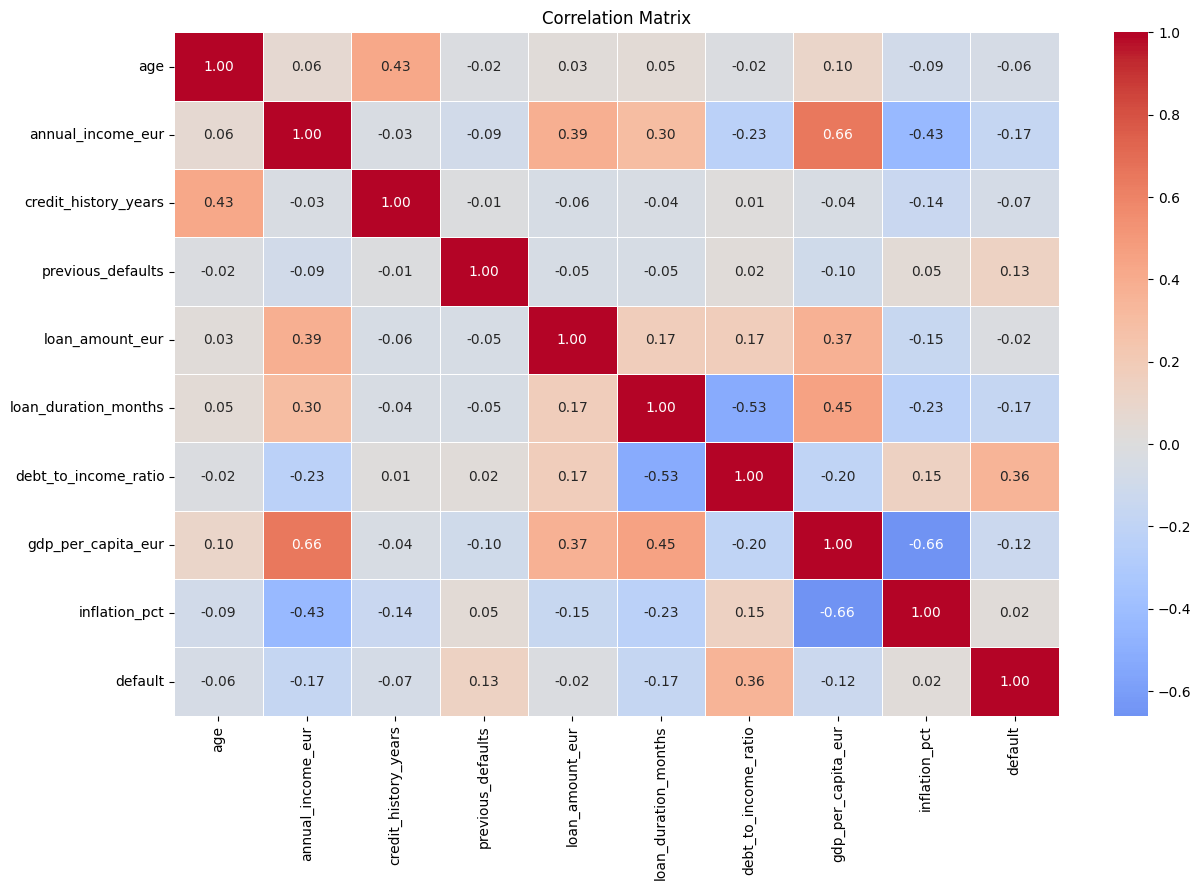

observation_id          0
country                 0
market_type             0
age                     0
employment_status       0
annual_income_eur       0
credit_history_years    0
previous_defaults       0
loan_amount_eur         0
loan_duration_months    0
debt_to_income_ratio    0
gdp_per_capita_eur      0
debt_to_gdp_pct         0
inflation_pct           0
interest_rate_pct       0
default                 0
dtype: int64

Total missed values: 0


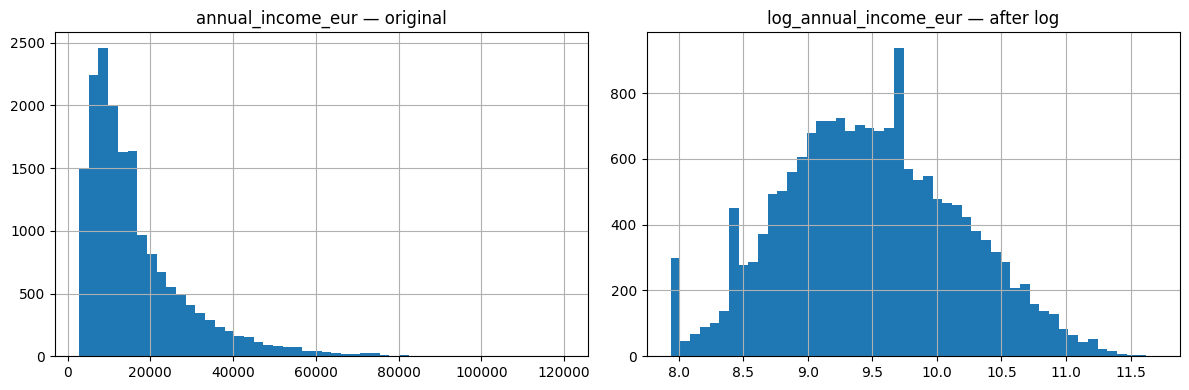

In [47]:
#cleaning and preparing our dataset
df = raw_df.copy()
# Veryfing how many missing datas we have into the dataset
print(df.isnull().sum())
print(df.isnull().mean() * 100) #in percentage


# Calculating the average of missing datas, for numerical variables only
numerical = ['age', 'annual_income_eur', 'credit_history_years',
             'previous_defaults', 'loan_amount_eur', 'loan_duration_months',
             'debt_to_income_ratio', 'gdp_per_capita_eur',
             'inflation_pct', 'default']

df[numerical] = df[numerical].fillna(df[numerical].mean())


# Most frequent value (mode) of missing datas, qualitative variables only
categorical = ['country', 'market_type', 'employment_status']
df[categorical] = df[categorical].fillna(df[categorical].mode().iloc[0])


# Verifying we have no more missing datas
print(df.isnull().sum())


# Correlation matrix, to see which variables we should exclude from dataset
corr_matrix = df[numerical].corr()

plt.figure(figsize=(13, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()


# Print high correlation pairs of variables
threshold = 0.75
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > threshold:
            print(f"{corr_matrix.columns[i]} ↔ {corr_matrix.columns[j]}: {val:.2f}")

# Double check if some datas are still missing
print(df.isnull().sum())
print(f"\nTotal missed values: {df.isnull().sum().sum()}")

# Logarithmic transformation to euro-expressed variables with high skewness, preparing the dataset for the Logistic Regression
LOG_VARS = ['annual_income_eur', 'loan_amount_eur', 'gdp_per_capita_eur']

for var in LOG_VARS:
    df[f'log_{var}'] = np.log1p(df[var]) # np.log1p is equal to log(1+x), we use it since is more reliable than simple log(x), it avoids bias that can occur if there are some zeros

# Visual veryfing before log/after log on annual_income
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['annual_income_eur'].hist(bins=50, ax=axes[0])
axes[0].set_title('annual_income_eur — original')
df['log_annual_income_eur'].hist(bins=50, ax=axes[1])
axes[1].set_title('log_annual_income_eur — after log')
plt.tight_layout()
plt.show()


[Logistic Regression] Country: Italy  |  Market: developed
Rows: 6000  |  Overall default rate: 0.0312
Training rows: 4800  |  Test rows: 1200
Defaults in test set: 37 out of 1200

ROC-AUC  = 0.9040
PR-AUC   = 0.3683
Brier    = 0.0247

[Logistic Regression] Country: Poland  |  Market: developed
Rows: 6000  |  Overall default rate: 0.0545
Training rows: 4800  |  Test rows: 1200
Defaults in test set: 65 out of 1200

ROC-AUC  = 0.8510
PR-AUC   = 0.3799
Brier    = 0.0419

[Logistic Regression] Country: Kazakhstan  |  Market: emerging
Rows: 5500  |  Overall default rate: 0.1185
Training rows: 4400  |  Test rows: 1100
Defaults in test set: 130 out of 1100

ROC-AUC  = 0.8540
PR-AUC   = 0.5290
Brier    = 0.0754


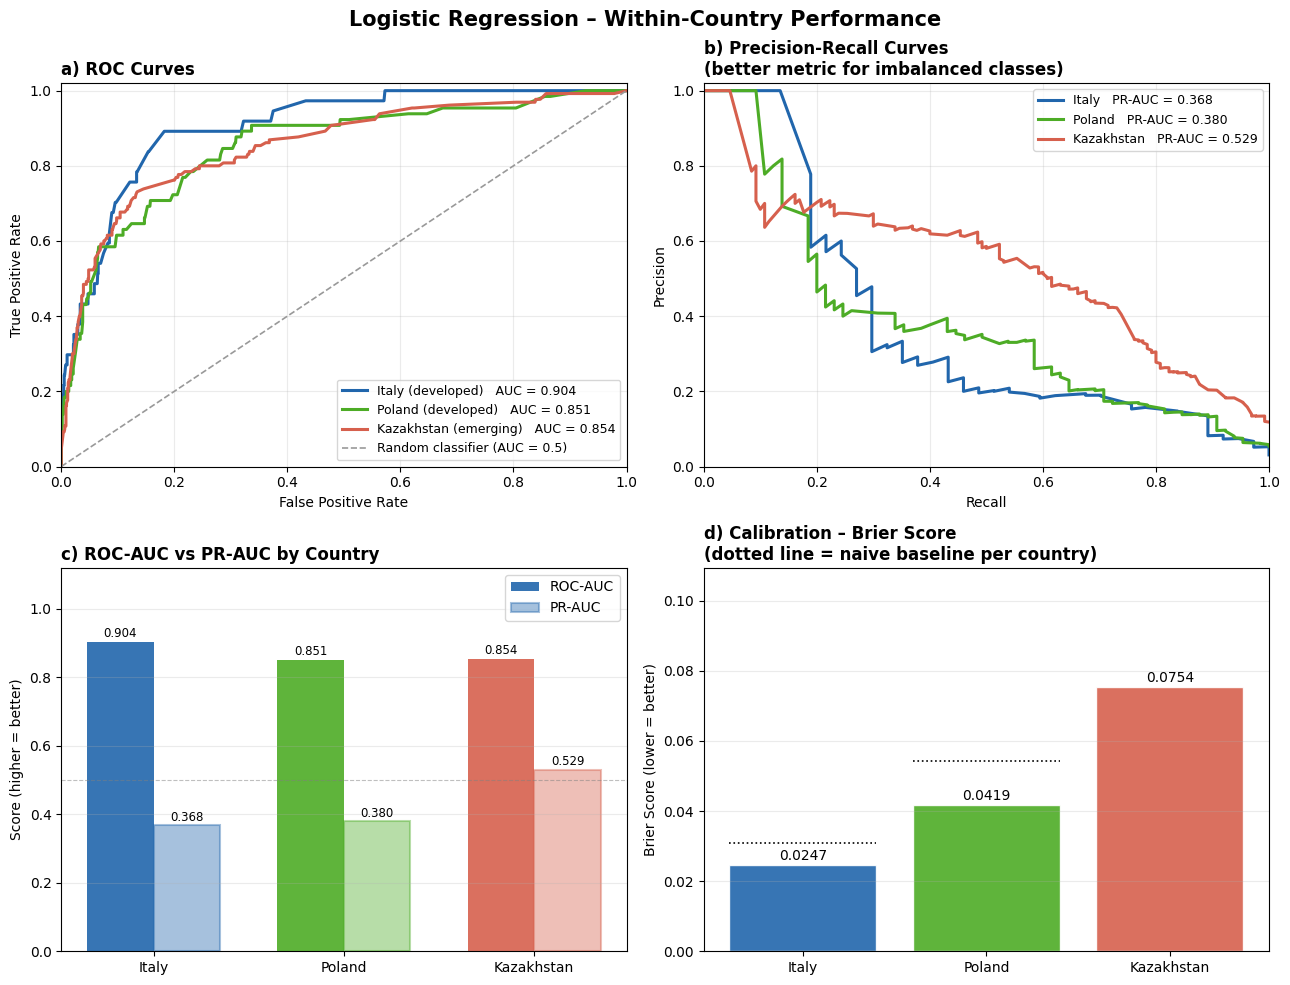

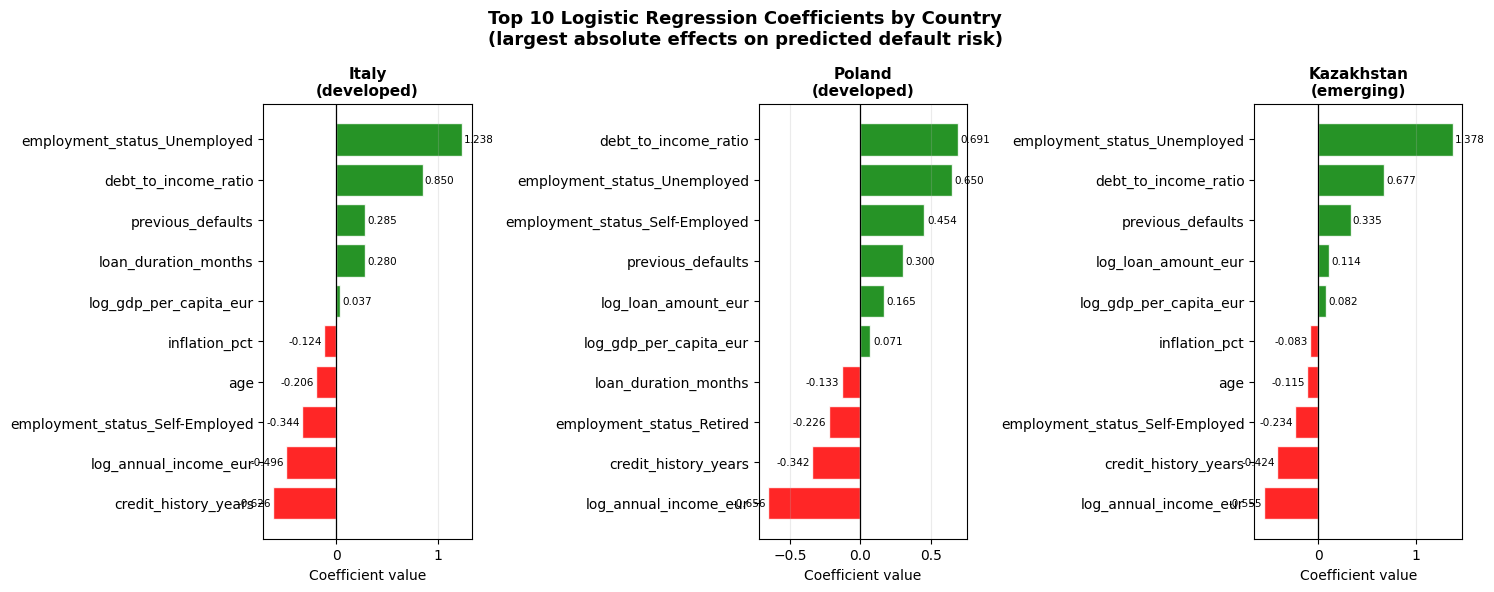

In [48]:
# LOGISTIC REGRESSION
# 1. Data preparation for Logistic Regression

df_lr = raw_df.drop(
    columns=["observation_id", "debt_to_gdp_pct", "interest_rate_pct"],
    errors="ignore"
)

X = df_lr.drop(columns=[TARGET_COLUMN])
y = df_lr[TARGET_COLUMN]

NUM_LOG_COLS = [col for col in numerical if col in LOG_VARS and col in X.columns] #. logarithmic transformation
NUM_OTHER_COLS = [col for col in numerical if col not in LOG_VARS and col in X.columns] # Other numerical variables stay normal
LR_CATEGORICAL = [col for col in categorical if col in X.columns]

# 2. Preprocessing

log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler()),
])

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first",
        sparse_output=False
    )),
])

preprocessor_lr = ColumnTransformer([           #Uses ColumnTransformer to selectively apply the numerical and categorical pipelines to their respective columns.
    ("num_log", log_pipeline, NUM_LOG_COLS),
    ("num", num_pipeline, NUM_OTHER_COLS),
    ("cat", cat_pipeline, LR_CATEGORICAL),
])

# 3. Logistic Regression model
model = Pipeline([           #Creates the final pipeline that chains the preprocessor with the classification model (LogisticRegression).
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(
       class_weight="balanced",
        random_state=42,
        max_iter=2000
    ))
])

# 4. Logistic Regression — Within-country evaluation
# with calibrated probabilities for better Brier Score

base_model = model
lr_results = {}

for country in COUNTRY_ORDER:

    country_df = df_lr[df_lr["country"] == country].copy()

    X_country = country_df.drop(columns=[TARGET_COLUMN])
    y_country = country_df[TARGET_COLUMN]

    X_train, X_test, y_train, y_test = train_test_split(  #Split Data with Stratification
        X_country,
        y_country,
        test_size=0.2,
        stratify=y_country,
        random_state=42                   #Divides the dataset into training (80%) and testing (20%) sets.
    )
# CALIBRATION NOTE: class_weight="balanced" causes the model to output exaggerated probabilities
    # (e.g. predicting 60% default risk when true rate is only 3%) to maximise recall.
    # This is intentional for loan approval decisions (catching defaulters matters most),
    # but inflates the Brier score. CalibratedClassifierCV wraps the model and adjusts
    # the raw probabilities to better reflect reality, bringing the Brier score down
    # without losing the good ROC-AUC performance. In a real bank this step would be
    # mandatory before using probabilities for interest rate pricing or regulatory reporting.

    lr_model_instance = CalibratedClassifierCV(
        clone(base_model),
        method="isotonic",
        cv=5
    )

    lr_model_instance.fit(X_train, y_train)

    y_pred = lr_model_instance.predict(X_test)
    y_proba = lr_model_instance.predict_proba(X_test)[:, 1]

    # Metrics
    auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    brier = brier_score_loss(y_test, y_proba)

    # Curves for plotting
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    prec, rec, _ = precision_recall_curve(y_test, y_proba)

    # Plain Logistic Regression model for coefficient analysis
    # We use the non-calibrated model here because coefficients
    # are the correct interpretability tool for Logistic Regression.

    coef_model = clone(base_model)
    coef_model.fit(X_train, y_train)

    lr_results[country] = {
        "calibrated_model": lr_model_instance,
        "coef_model": coef_model,
        "auc": auc,
        "pr_auc": pr_auc,
        "brier_score": brier,
        "fpr": fpr,
        "tpr": tpr,
        "prec": prec,
        "rec": rec,
        "y_test": y_test,
        "y_proba": y_proba
    }

    print(f"\n{'='*55}")
    print(f"[Logistic Regression] Country: {country}  |  Market: {MARKET_TYPE[country]}")
    print(f"Rows: {len(country_df)}  |  Overall default rate: {y_country.mean():.4f}")
    print(f"Training rows: {len(X_train)}  |  Test rows: {len(X_test)}")
    print(f"Defaults in test set: {y_test.sum()} out of {len(y_test)}")
    print(f"\nROC-AUC  = {auc:.4f}")
    print(f"PR-AUC   = {pr_auc:.4f}")
    print(f"Brier    = {brier:.4f}")


# 5. Logistic Regression — Performance graphs
# ROC curves + PR curves + ROC-AUC/PR-AUC + calibrated Brier Score

fig_lr, axes_lr = plt.subplots(2, 2, figsize=(13, 10))

fig_lr.suptitle(
    "Logistic Regression – Within-Country Performance",
    fontsize=15,
    fontweight="bold"
)

# Chart 1: ROC Curves

ax = axes_lr[0, 0]

for c in COUNTRY_ORDER:
    r = lr_results[c]

    ax.plot(
        r["fpr"],
        r["tpr"],
        color=COLORS[c],
        lw=2.2,
        label=f"{c} ({MARKET_TYPE[c]})   AUC = {r['auc']:.3f}"
    )

ax.plot(
    [0, 1],
    [0, 1],
    "--",
    color="#999999",
    lw=1.2,
    label="Random classifier (AUC = 0.5)"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("a) ROC Curves", fontweight="bold", loc="left")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

# Chart 2: Precision-Recall Curves

ax = axes_lr[0, 1]

for c in COUNTRY_ORDER:
    r = lr_results[c]

    ax.plot(
        r["rec"],
        r["prec"],
        color=COLORS[c],
        lw=2.2,
        label=f"{c}   PR-AUC = {r['pr_auc']:.3f}"
    )

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(
    "b) Precision-Recall Curves\n(better metric for imbalanced classes)",
    fontweight="bold",
    loc="left"
)
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

# Chart 3: ROC-AUC vs PR-AUC

ax = axes_lr[1, 0]

x = np.arange(len(COUNTRY_ORDER))
w = 0.35

bars_roc = ax.bar(
    x - w/2,
    [lr_results[c]["auc"] for c in COUNTRY_ORDER],
    w,
    color=[COLORS[c] for c in COUNTRY_ORDER],
    alpha=0.9,
    label="ROC-AUC"
)

bars_pr = ax.bar(
    x + w/2,
    [lr_results[c]["pr_auc"] for c in COUNTRY_ORDER],
    w,
    color=[COLORS[c] for c in COUNTRY_ORDER],
    alpha=0.4,
    edgecolor=[COLORS[c] for c in COUNTRY_ORDER],
    linewidth=1.5,
    label="PR-AUC"
)

label_bars(ax, list(bars_roc) + list(bars_pr))

ax.set_xticks(x)
ax.set_xticklabels(COUNTRY_ORDER)
ax.set_ylabel("Score (higher = better)")
ax.set_title("c) ROC-AUC vs PR-AUC by Country", fontweight="bold", loc="left")
ax.legend()
ax.set_ylim(0, 1.12)
ax.grid(axis="y", alpha=0.25)
ax.axhline(0.5, color="grey", lw=0.8, ls="--", alpha=0.5)

# Chart 4: Brier Score

ax = axes_lr[1, 1]

brier_vals = [lr_results[c]["brier_score"] for c in COUNTRY_ORDER]

bars_b = ax.bar(
    COUNTRY_ORDER,
    brier_vals,
    color=[COLORS[c] for c in COUNTRY_ORDER],
    alpha=0.9,
    edgecolor="white"
)

label_bars(ax, bars_b, fmt=".4f", pad=0.0005, fontsize=10)

# Dotted line = naive baseline per country
# The naive baseline predicts the observed test-set default rate for everyone.

for i, c in enumerate(COUNTRY_ORDER):
    baseline = lr_results[c]["y_test"].mean()

    ax.hlines(
        baseline,
        xmin=i - 0.4,
        xmax=i + 0.4,
        colors="black",
        lw=1.2,
        linestyles="dotted"
    )

ax.set_ylabel("Brier Score (lower = better)")
ax.set_title(
    "d) Calibration – Brier Score\n"
    "(dotted line = naive baseline per country)",
    fontweight="bold",
    loc="left"
)

ax.set_ylim(0, max(brier_vals) * 1.45)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# 7. Logistic Regression — Top 10 coefficients by country
# Positive coefficient = increases predicted default risk.
# Negative coefficient = reduces predicted default risk.

fig_lr_imp, axes = plt.subplots(1, 3, figsize=(15, 6))

fig_lr_imp.suptitle(
    "Top 10 Logistic Regression Coefficients by Country\n"
    "(largest absolute effects on predicted default risk)",
    fontsize=13,
    fontweight="bold"
)

for ax, country in zip(axes, COUNTRY_ORDER):

    lr_model = lr_results[country]["coef_model"]

    pre_stp = lr_model.named_steps["preprocessor"]
    clf = lr_model.named_steps["classifier"]

    feat_names = pre_stp.get_feature_names_out()

    clean_names = [
        n.replace("num_log__", "log_")
         .replace("num__", "")
         .replace("cat__", "")
         .replace("_x0_", "=")
        for n in feat_names
    ]

    coefs = clf.coef_[0]     #Retrieves the coefficients of the logistic regression model. A larger coefficient (in absolute value) indicates a greater influence on the probability of default.

    coef_df = pd.DataFrame({
        "Feature": clean_names,
        "Coefficient": coefs
    })

    coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs() # Converts coefficients to absolute values so we can identify the strongest effects,
# whether they increase or decrease predicted default risk.

    top10 = coef_df.nlargest(10, "Abs_Coefficient").sort_values("Coefficient")
    bar_colors = [
        "green" if val > 0 else "red"
        for val in top10["Coefficient"]
    ]

    ax.barh(
        top10["Feature"],
        top10["Coefficient"],
        color=bar_colors,
        alpha=0.85,
        edgecolor="white"
    )

    ax.axvline(0, color="black", lw=0.9)

    ax.set_title(
        f"{country}\n({MARKET_TYPE[country]})",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlabel("Coefficient value")
    ax.grid(axis="x", alpha=0.25)

    for i, val in enumerate(top10["Coefficient"]):
        ax.text(
            val + 0.02 if val > 0 else val - 0.02,
            i,
            f"{val:.3f}",
            va="center",
            ha="left" if val > 0 else "right",
            fontsize=7.5
        )

plt.tight_layout()
plt.show()


Train: Italy        -> Test: Italy        AUC = 0.904
Train: Italy        -> Test: Poland       AUC = 0.834
Train: Italy        -> Test: Kazakhstan   AUC = 0.835
Train: Poland       -> Test: Italy        AUC = 0.878
Train: Poland       -> Test: Poland       AUC = 0.851
Train: Poland       -> Test: Kazakhstan   AUC = 0.834
Train: Kazakhstan   -> Test: Italy        AUC = 0.886
Train: Kazakhstan   -> Test: Poland       AUC = 0.841
Train: Kazakhstan   -> Test: Kazakhstan   AUC = 0.854


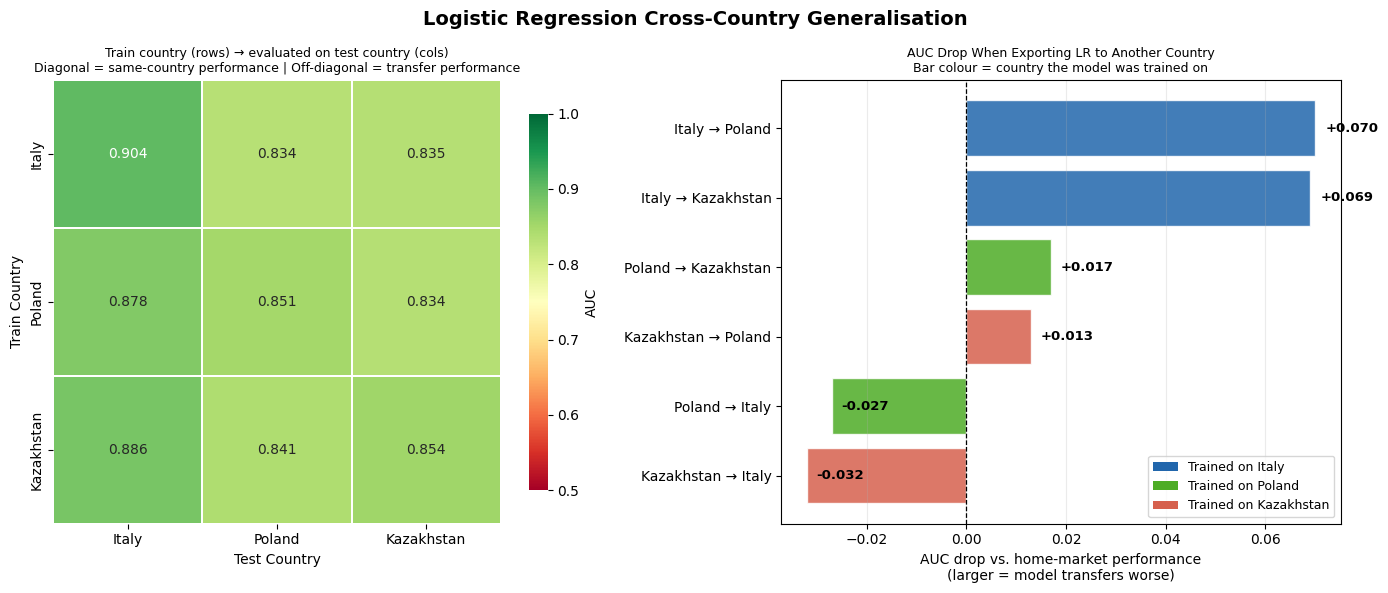

In [49]:
#logistic regression- cross country generalisation
base_model = model

full_df_lr = df_lr.copy() #Creates a copy of the full DataFrame df to avoid modifying the original during processing.

cross_country_auc = pd.DataFrame(index=COUNTRY_ORDER, columns=COUNTRY_ORDER, dtype=float) # Initializes an empty DataFrame named cross_country_auc. This DataFrame will have country names as row indices and column names, and will be used to store the resulting AUC scores from the cross-training and testing.

for train_country in COUNTRY_ORDER: #This loop iterates through each country in the COUNTRY_ORDER list. For each iteration:
    train_group = full_df_lr[full_df_lr["country"] == train_country].copy()

    X_train_country = train_group.drop(columns=[TARGET_COLUMN])
    y_train_country = train_group[TARGET_COLUMN]

    model_country = clone(base_model) # A new instance of the base model is created. This is crucial to ensure that each model trained on a specific country is independent of the others.
    model_country.fit(X_train_country, y_train_country)

    for test_country in COUNTRY_ORDER: #For each trained model (model_country), this loop iterates through all countries (including others and the training country itself).

        # Use honest within-country holdout AUC on diagonal
        if train_country == test_country:
            cross_country_auc.loc[train_country, test_country] = lr_results[test_country]["auc"]
            print(f"Train: {train_country:<12} -> Test: {test_country:<12} AUC = {lr_results[test_country]['auc']:.3f}")
            continue

        test_group = full_df_lr[full_df_lr["country"] == test_country].copy()

        X_test_country = test_group.drop(columns=[TARGET_COLUMN])
        y_test_country = test_group[TARGET_COLUMN]

        y_prob_country = model_country.predict_proba(X_test_country)[:, 1] # The trained model (from train_country) is used to make probability predictions on the test_country's data.
        auc = roc_auc_score(y_test_country, y_prob_country)

        cross_country_auc.loc[train_country, test_country] = auc #The calculated AUC score is stored in the cross_country_auc DataFrame, at the row corresponding to the train_country and the column corresponding to the test_country.

        print(f"Train: {train_country:<12} -> Test: {test_country:<12} AUC = {auc:.3f}")

#Figures
fig_lr, axes_lr = plt.subplots(1, 2, figsize=(14, 6))
fig_lr.suptitle("Logistic Regression Cross-Country Generalisation",
                fontsize=14, fontweight="bold")
# Heatmap- makes it easy to visually grasp how well a model trained on one country generalizes (or doesn't generalize) to other countries. Darker colors indicate better performance (higher AUC).
# Chart 1: Heatmap
ax = axes_lr[0]
sns.heatmap(cross_country_auc.astype(float), annot=True, fmt=".3f",
            cmap="RdYlGn", vmin=0.5, vmax=1.0,
            ax=ax, linewidths=1.2, linecolor="white",
            cbar_kws={"label": "AUC", "shrink": 0.85})
ax.set_title("Train country (rows) → evaluated on test country (cols)\n"
             "Diagonal = same-country performance | Off-diagonal = transfer performance",
             fontsize=9)
ax.set_xlabel("Test Country")
ax.set_ylabel("Train Country")

# Chart 2: AUC Drop bar chart
ax = axes_lr[1]

drop_records = [
    {"Label": f"{tc} → {ec}",
     "Drop":  round(float(cross_country_auc.loc[tc, tc]) - float(cross_country_auc.loc[tc, ec]), 3),
     "Train": tc}
    for tc in COUNTRY_ORDER
    for ec in COUNTRY_ORDER if ec != tc
]
drop_df    = pd.DataFrame(drop_records).sort_values("Drop", ascending=True)
bar_colors = [COLORS[r["Train"]] for _, r in drop_df.iterrows()]

bars = ax.barh(drop_df["Label"], drop_df["Drop"],
               color=bar_colors, alpha=0.85, edgecolor="white")

for bar, val in zip(bars, drop_df["Drop"]):
    ax.text(bar.get_width() + 0.002,
            bar.get_y() + bar.get_height() / 2,
            f"{val:+.3f}", va="center", fontsize=9.5, fontweight="bold")

ax.axvline(0, color="black", lw=0.9, ls="--")
ax.set_xlabel("AUC drop vs. home-market performance\n(larger = model transfers worse)")
ax.set_title("AUC Drop When Exporting LR to Another Country\n"
             "Bar colour = country the model was trained on", fontsize=9)
ax.grid(axis="x", alpha=0.25)
ax.legend(handles=[Patch(facecolor=COLORS[c], label=f"Trained on {c}") for c in COUNTRY_ORDER],
          fontsize=9, loc="lower right")

plt.tight_layout()
plt.show()

In [50]:
# SHARED SETUP (used by Random forest and XGBoost

# Data for RF and XGBoost — loaded from raw_df, only observation_id dropped
full_df = raw_df.drop(columns=["observation_id"], errors="ignore")

# Column types detected ONCE — reused by both RF and XGBoost
numeric_features     = full_df.drop(columns=[TARGET_COLUMN]).select_dtypes(include=np.number).columns.tolist()
categorical_features = full_df.drop(columns=[TARGET_COLUMN]).select_dtypes(exclude=np.number).columns.tolist()

# Transformers— identical in both RF and XGBoost
# fills missing values with median + adds a binary flag where values were missing (useful for Kazakhstan)
numeric_transformer = SimpleImputer(strategy="median", add_indicator=True)

# fills missing categories with most frequent + converts to 0/1 columns
# handle_unknown="ignore" → new categories in test data become all zeros
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

# Preprocessor defined ONCE — identical in both RF and XGBoost
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer,     numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

def label_bars(ax, bars, fmt=".3f", pad=0.005, fontsize=8.5):
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + pad,
            f"{bar.get_height():{fmt}}",
            ha="center", va="bottom", fontsize=fontsize,
        )

In [51]:
#RANDOM FOREST

def build_rf_pipeline():
    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=20,
        min_samples_split=40,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42
    )
    calibrated_rf = CalibratedClassifierCV(
        estimator=rf,
        method="sigmoid",
        cv=3
    )

    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", calibrated_rf),
    ])

In [52]:
# STEP 2 – Within-country evaluation (80/20 split)
results = {}

for country in COUNTRY_ORDER:
    group = full_df[full_df["country"] == country]

    X = group.drop(columns=[TARGET_COLUMN])
    y = group[TARGET_COLUMN]

    # we split into 80% training and 20% test, stratify=y : ensures the test set has the same default rate as training
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    model = build_rf_pipeline()
    model.fit(X_train, y_train)

    # Predicting probabilities, [[prob_no_default, prob_default], ...]
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    # ROC-AUC: probability that model ranks a real defaulter above a non-defaulter
    auc = roc_auc_score(y_test, y_pred_proba)
    # PR-AUC: more 'honest' metric when default classes are very imbalanced
    pr_auc = average_precision_score(y_test, y_pred_proba)
    # Brier Score: measures accuracy of the predicted probabilities, if model assigns 5% default probability but true rate is 12%, Brier captures this error
    brier = brier_score_loss(y_test, y_pred_proba)

    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)          # gives the full ROC curve coordinates (for plotting)
    prec, rec, _ = precision_recall_curve(y_test, y_pred_proba)

    results[country] = {
        "model":        model,
        "auc":          auc,
        "pr_auc":       pr_auc,
        "brier":        brier,
        "fpr":          fpr,
        "tpr":          tpr,
        "prec":         prec,
        "rec":          rec,
        "y_test":       y_test,
        "y_pred_proba": y_pred_proba,
    }

    print(f"\n{'='*55}")
    print(f"Country: {country}  |  Market: {MARKET_TYPE[country]}")
    print(f"Rows: {len(group)}  |  Overall default rate: {y.mean():.4f}")
    print(f"Training rows: {len(X_train)}  |  Test rows: {len(X_test)}")
    print(f"Defaults in test set: {y_test.sum()} out of {len(y_test)}")
    print(f"\nROC-AUC  = {auc:.4f}")
    print(f"PR-AUC   = {pr_auc:.4f}")
    print(f"Brier    = {brier:.4f}")


Country: Italy  |  Market: developed
Rows: 6000  |  Overall default rate: 0.0312
Training rows: 4800  |  Test rows: 1200
Defaults in test set: 37 out of 1200

ROC-AUC  = 0.9250
PR-AUC   = 0.3684
Brier    = 0.0248

Country: Poland  |  Market: developed
Rows: 6000  |  Overall default rate: 0.0545
Training rows: 4800  |  Test rows: 1200
Defaults in test set: 65 out of 1200

ROC-AUC  = 0.8242
PR-AUC   = 0.3272
Brier    = 0.0434

Country: Kazakhstan  |  Market: emerging
Rows: 5500  |  Overall default rate: 0.1185
Training rows: 4400  |  Test rows: 1100
Defaults in test set: 130 out of 1100

ROC-AUC  = 0.8451
PR-AUC   = 0.5003
Brier    = 0.0767


In [53]:
# STEP 3 – Cross-country evaluation
# NOTE: Models here are trained on 100% of each country's data —no held-out set is needed because the other country IS the test set.
# The diagonal is replaced post-hoc with within-country AUC from Step 2.
heatmap_data = pd.DataFrame(index=COUNTRY_ORDER, columns=COUNTRY_ORDER, dtype=float)

for train_country in COUNTRY_ORDER:
    train_group = full_df[full_df["country"] == train_country]
    X_tr = train_group.drop(columns=[TARGET_COLUMN])
    y_tr = train_group[TARGET_COLUMN]

    cross_model = build_rf_pipeline()
    cross_model.fit(X_tr, y_tr)

    for test_country in COUNTRY_ORDER:
        test_group = full_df[full_df["country"] == test_country]
        X_te = test_group.drop(columns=[TARGET_COLUMN])
        y_te = test_group[TARGET_COLUMN]

        y_pred = cross_model.predict_proba(X_te)[:, 1]
        heatmap_data.loc[train_country, test_country] = round(roc_auc_score(y_te, y_pred), 3)
  # Replacing diagonal with within-country holdout AUC (more honest estimate)
for c in COUNTRY_ORDER:
    heatmap_data.loc[c, c] = results[c]["auc"]

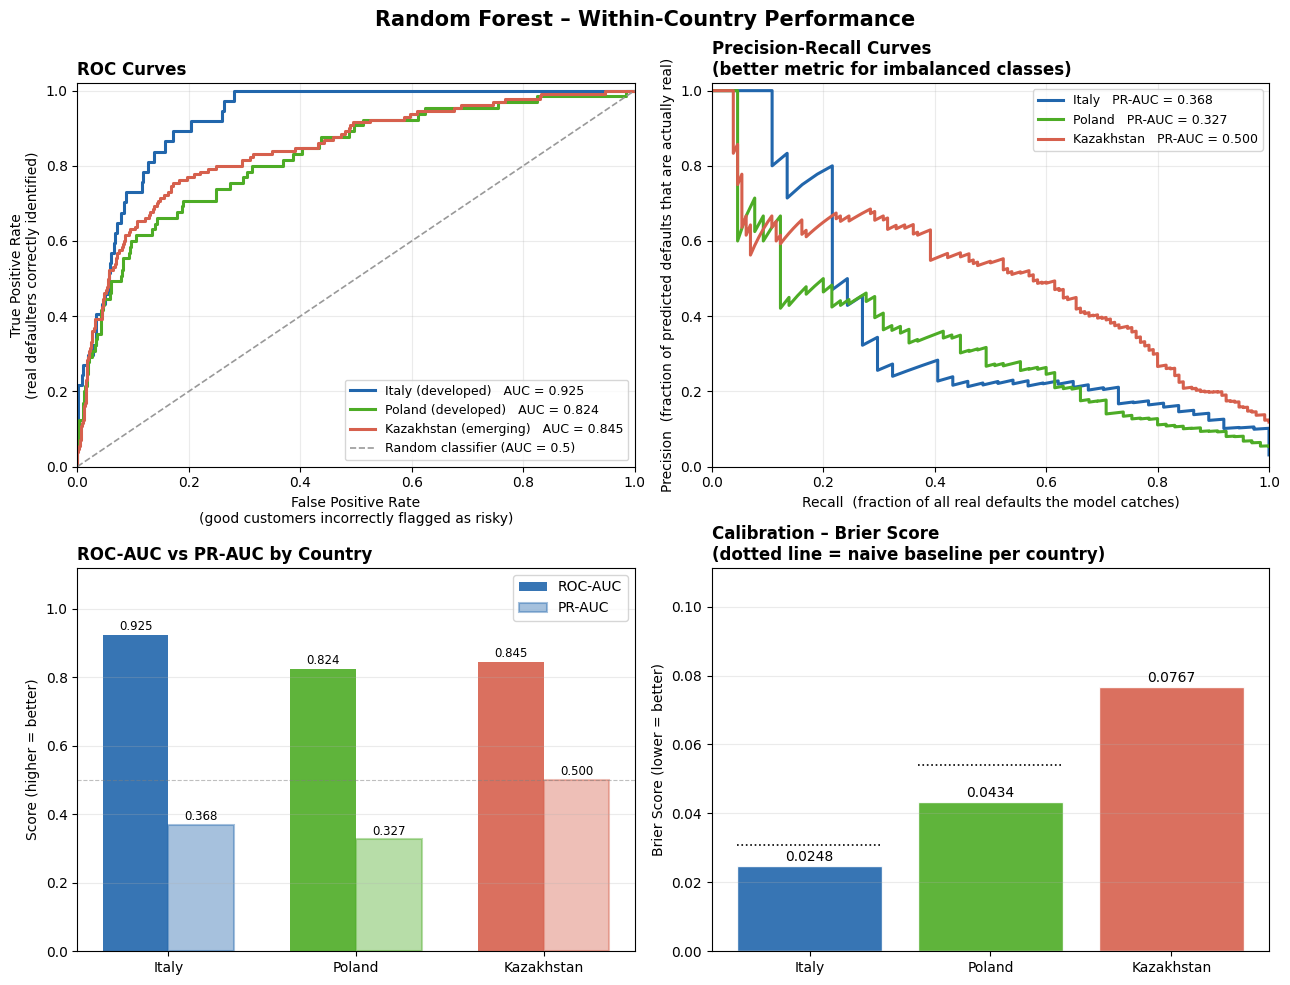

In [54]:
# FIGURE 1 – Within-country performance
fig1, axes = plt.subplots(2, 2, figsize=(13, 10))
fig1.suptitle("Random Forest – Within-Country Performance",
              fontsize=15, fontweight="bold")

# Chart 1a: ROC Curves
# trade-off between catching real defaults (recall) and raising false alarms
ax = axes[0, 0]
for c in COUNTRY_ORDER:
    r = results[c]
    ax.plot(r["fpr"], r["tpr"], color=COLORS[c], lw=2.2,
            label=f"{c} ({MARKET_TYPE[c]})   AUC = {r['auc']:.3f}")
ax.plot([0, 1], [0, 1], "--", color="#999999", lw=1.2, label="Random classifier (AUC = 0.5)")
ax.set_xlabel("False Positive Rate\n(good customers incorrectly flagged as risky)")
ax.set_ylabel("True Positive Rate\n(real defaulters correctly identified)")
ax.set_title("ROC Curves", fontweight="bold", loc="left")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

# Chart 1b: Precision-Recall Curves
# more informative than ROC when defaults are rare
ax = axes[0, 1]
for c in COUNTRY_ORDER:
    r = results[c]
    ax.plot(r["rec"], r["prec"], color=COLORS[c], lw=2.2,
            label=f"{c}   PR-AUC = {r['pr_auc']:.3f}")
ax.set_xlabel("Recall  (fraction of all real defaults the model catches)")
ax.set_ylabel("Precision  (fraction of predicted defaults that are actually real)")
ax.set_title("Precision-Recall Curves\n(better metric for imbalanced classes)",
             fontweight="bold", loc="left")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

# Chart 1c: ROC-AUC vs PR-AUC grouped bar chart
ax = axes[1, 0]
x = np.arange(len(COUNTRY_ORDER))
w = 0.35

bars_roc = ax.bar(x - w/2, [results[c]["auc"]    for c in COUNTRY_ORDER], w,
                  color=[COLORS[c] for c in COUNTRY_ORDER], alpha=0.9, label="ROC-AUC")
bars_pr  = ax.bar(x + w/2, [results[c]["pr_auc"] for c in COUNTRY_ORDER], w,
                  color=[COLORS[c] for c in COUNTRY_ORDER], alpha=0.4,
                  edgecolor=[COLORS[c] for c in COUNTRY_ORDER], linewidth=1.5, label="PR-AUC")

label_bars(ax, list(bars_roc) + list(bars_pr))

ax.set_xticks(x)
ax.set_xticklabels(COUNTRY_ORDER)
ax.set_ylabel("Score (higher = better)")
ax.set_title("ROC-AUC vs PR-AUC by Country", fontweight="bold", loc="left")
ax.legend()
ax.set_ylim(0, 1.12)
ax.grid(axis="y", alpha=0.25)
ax.axhline(0.5, color="grey", lw=0.8, ls="--", alpha=0.5)

# Chart 1d: Brier Score
# how well-calibrated the predicted probabilities are; lower Brier = better calibration
ax = axes[1, 1]
brier_vals = [results[c]["brier"] for c in COUNTRY_ORDER]
bars_b = ax.bar(COUNTRY_ORDER, brier_vals,
                color=[COLORS[c] for c in COUNTRY_ORDER], alpha=0.9, edgecolor="white")

label_bars(ax, bars_b, fmt=".4f", pad=0.0005, fontsize=10)

# Baseline: naive model that always predicts the mean default rate
for i, c in enumerate(COUNTRY_ORDER):
    baseline = results[c]["y_test"].mean()
    ax.hlines(baseline, xmin=i - 0.4, xmax=i + 0.4,
              colors="black", lw=1.2, linestyles="dotted")

ax.set_ylabel("Brier Score (lower = better)")
ax.set_title("Calibration – Brier Score\n"
             "(dotted line = naive baseline per country)",
             fontweight="bold", loc="left")
ax.set_ylim(0, max(brier_vals) * 1.45)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

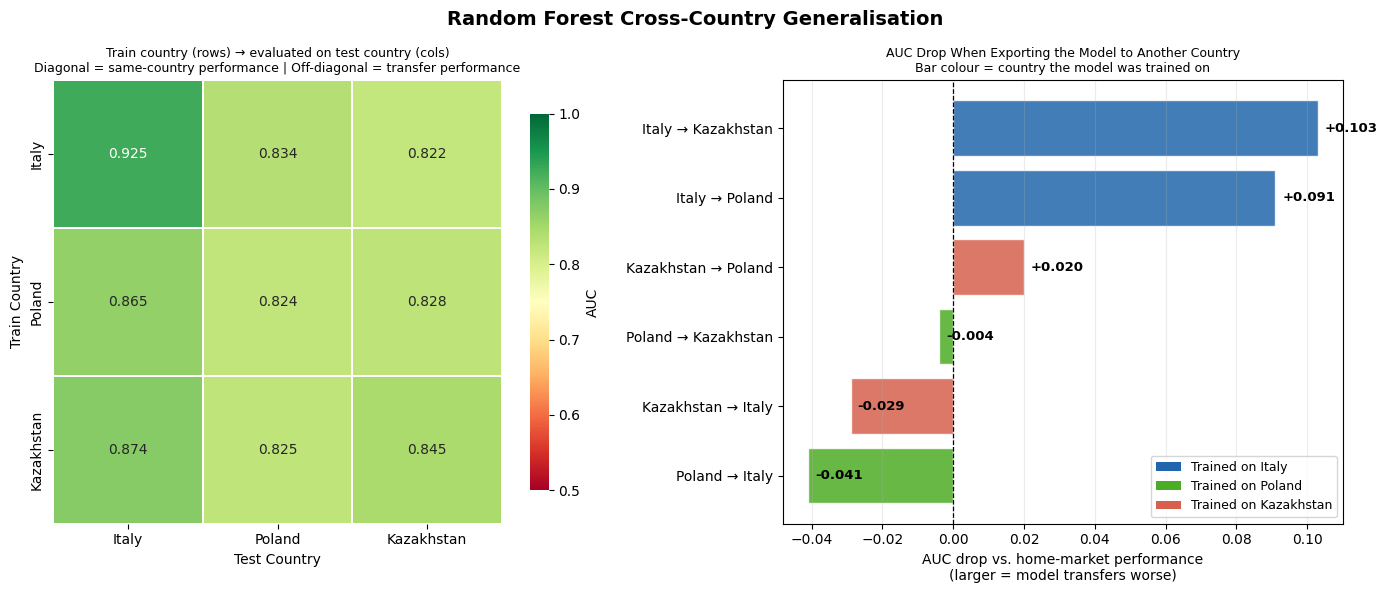

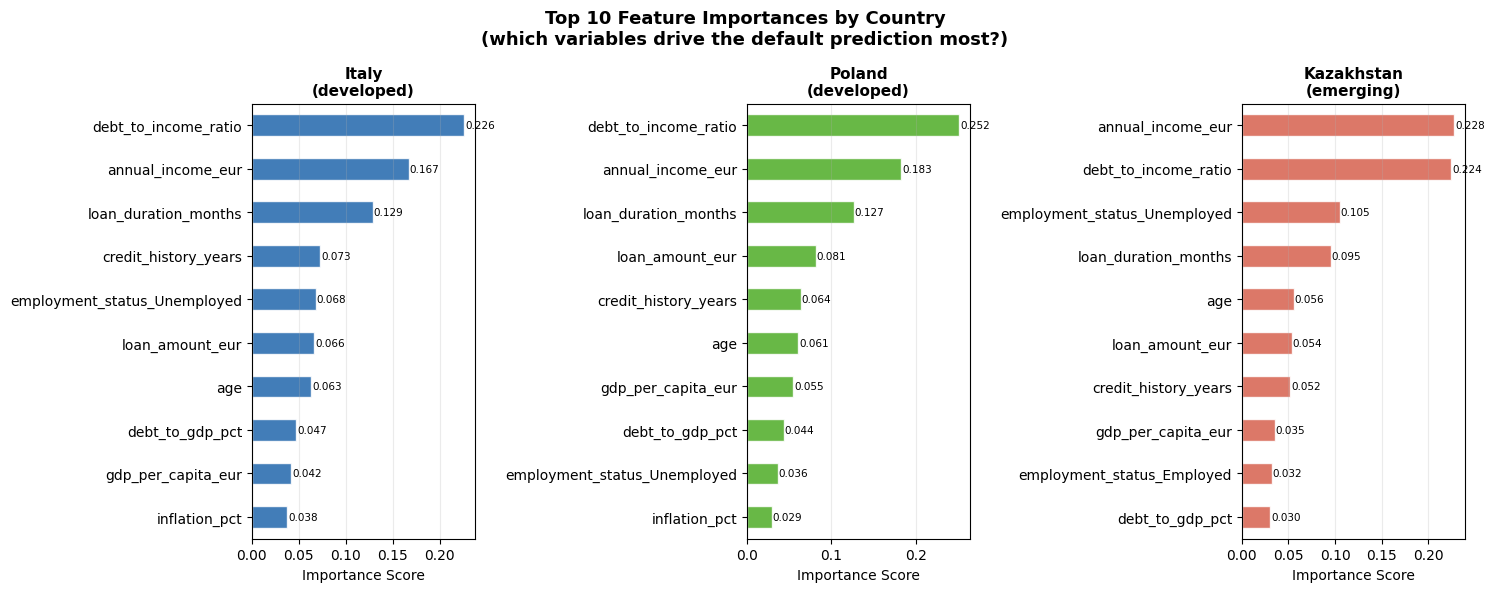

In [55]:
# FIGURE 2 – Cross-country generalisation
fig2, axes = plt.subplots(1, 2, figsize=(14, 6))
fig2.suptitle("Random Forest Cross-Country Generalisation",
              fontsize=14, fontweight="bold")

# Chart 2a: Heatmap
ax = axes[0]
sns.heatmap(heatmap_data, annot=True, fmt=".3f",
            cmap="RdYlGn", vmin=0.5, vmax=1.0,
            ax=ax, linewidths=1.2, linecolor="white",
            cbar_kws={"label": "AUC", "shrink": 0.85})
ax.set_title("Train country (rows) → evaluated on test country (cols)\n"
             "Diagonal = same-country performance | Off-diagonal = transfer performance",
             fontsize=9)
ax.set_xlabel("Test Country")
ax.set_ylabel("Train Country")

# Chart 2b: AUC Drop bar chart
ax = axes[1]

drop_records = [
    {"Label": f"{tc} → {ec}",
     "Drop":  round(float(heatmap_data.loc[tc, tc]) - float(heatmap_data.loc[tc, ec]), 3),
     "Train": tc}
    for tc in COUNTRY_ORDER
    for ec in COUNTRY_ORDER if ec != tc
]
drop_df    = pd.DataFrame(drop_records).sort_values("Drop", ascending=True)
bar_colors = [COLORS[r["Train"]] for _, r in drop_df.iterrows()]

bars = ax.barh(drop_df["Label"], drop_df["Drop"],
               color=bar_colors, alpha=0.85, edgecolor="white")

for bar, val in zip(bars, drop_df["Drop"]):
    ax.text(bar.get_width() + 0.002,
            bar.get_y() + bar.get_height() / 2,
            f"{val:+.3f}", va="center", fontsize=9.5, fontweight="bold")

ax.axvline(0, color="black", lw=0.9, ls="--")
ax.set_xlabel("AUC drop vs. home-market performance\n(larger = model transfers worse)")
ax.set_title("AUC Drop When Exporting the Model to Another Country\n"
             "Bar colour = country the model was trained on", fontsize=9)
ax.grid(axis="x", alpha=0.25)

legend_elements = [Patch(facecolor=COLORS[c], label=f"Trained on {c}") for c in COUNTRY_ORDER]
ax.legend(handles=legend_elements, fontsize=9, loc="lower right")

plt.tight_layout()
plt.show()


# FIGURE 3 – Feature importances
# WHICH variables the Random Forest relies on most in each country
fig3, axes = plt.subplots(1, 3, figsize=(15, 6))
fig3.suptitle("Top 10 Feature Importances by Country\n"
              "(which variables drive the default prediction most?)",
              fontsize=13, fontweight="bold")

for ax, country in zip(axes, COUNTRY_ORDER):
    r       = results[country]
    rf_mdl  = r["model"].named_steps["classifier"]
    pre_stp = r["model"].named_steps["preprocessor"]

    feat_names = pre_stp.get_feature_names_out()

    # Strip sklearn prefixes; convert one-hot suffix (e.g. "cat__status_x0_Employed")
    # to a readable label (e.g. "status=Employed")
    clean_names = [
        n.replace("num__", "").replace("cat__", "").replace("_x0_", "=")
        for n in feat_names
    ]

    importances = pd.Series(rf_mdl.calibrated_classifiers_[0].estimator.feature_importances_, index=clean_names)
    top10 = importances.nlargest(10).sort_values()

    top10.plot.barh(ax=ax, color=COLORS[country], alpha=0.85, edgecolor="white")
    ax.set_title(f"{country}\n({MARKET_TYPE[country]})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Importance Score")
    ax.grid(axis="x", alpha=0.25)

    for i, val in enumerate(top10.values):
        ax.text(val + 0.001,
                i,
                f"{val:.3f}", va="center", fontsize=7.5)

plt.tight_layout()
plt.show()

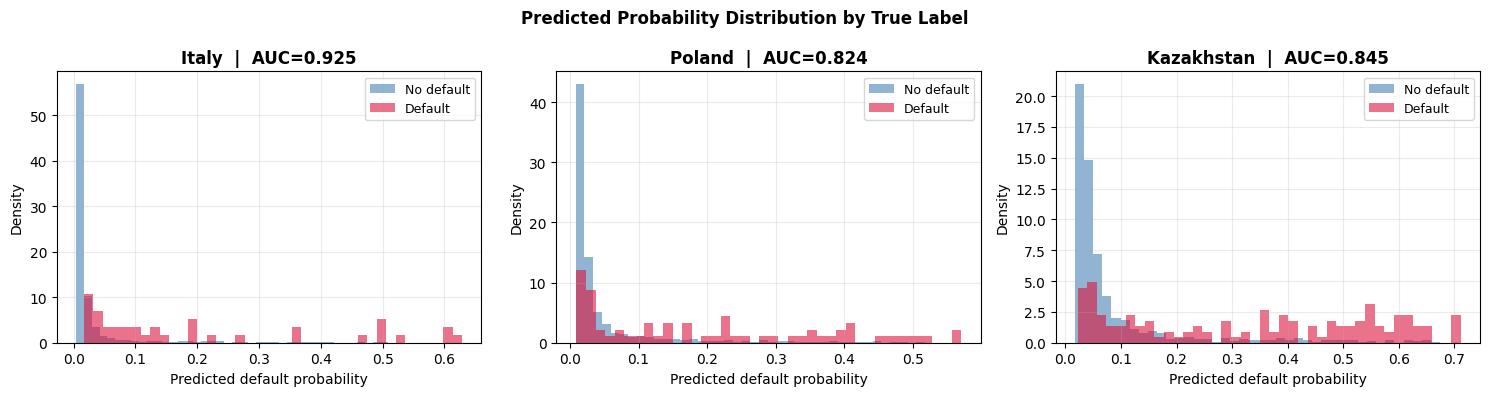

In [56]:
# Additional figure to understand why Poland shows weaker model performance compared to Italy and Kazakhstan.

# Italy:
# Most non-defaulters (blue) are concentrated extremely close to zero, while defaulters (red) extend further to the right.
# This indicates strong ranking ability and explains the high ROC-AUC (~0.93),

# Poland:
# The two distributions overlap more heavily, especially at low probability values.
# Many defaulters receive probabilities similar to non-defaulters, making separation more difficult and reducing ROC-AUC (~0.82).

# Kazakhstan:
# Defaulters generally receive higher predicted probabilities than non-defaulters, although overlap still exists near low probability ranges.
# The higher default rate likely provides more positive examples, helping the model identify default-related patterns more effectively.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Predicted Probability Distribution by True Label", fontweight="bold")

for ax, country in zip(axes, COUNTRY_ORDER):
    r = results[country]

    proba_default     = r["y_pred_proba"][r["y_test"] == 1]
    proba_non_default = r["y_pred_proba"][r["y_test"] == 0]

    ax.hist(proba_non_default, bins=40, alpha=0.6,
            color="steelblue", label="No default", density=True)
    ax.hist(proba_default,     bins=40, alpha=0.6,
            color="crimson",   label="Default",    density=True)

    ax.set_title(f"{country}  |  AUC={r['auc']:.3f}", fontweight="bold")
    ax.set_xlabel("Predicted default probability")
    ax.set_ylabel("Density")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [57]:
# XGBOOST model
# Same idea as above: preprocess the data, train one model per country, evaluate it, and then test how well it transfers

# STEP 1 – building an XGBoost model
def build_xgb_pipeline(y):
    # XGBoost has no built-in class_weight — scale_pos_weight is the only thing unique to XGBoost
    positives        = max(int(y.sum()), 1)
    scale_pos_weight = (len(y) - positives) / positives

    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier",   XGBClassifier(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=1,
    reg_lambda=2,
    eval_metric="logloss",
    random_state=42
        )),
    ])

In [58]:
# STEP 2 – training and evaluating within each country
xgb_results = {}

for country in COUNTRY_ORDER:
    group = full_df[full_df["country"] == country]

    print(f"\n{'='*55}")
    print(f"[XGBoost] Country: {country}  |  Market: {MARKET_TYPE[country]}")
    print(f"Rows: {len(group)}  |  Overall default rate: {group[TARGET_COLUMN].mean():.4f}")

    X = group.drop(columns=[TARGET_COLUMN])
    y = group[TARGET_COLUMN]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    print(f"Training rows: {len(X_train)}  |  Test rows: {len(X_test)}")
    print(f"Defaults in test set: {y_test.sum()} out of {len(y_test)}")

    model = build_xgb_pipeline(y_train)
    model.fit(X_train, y_train)

    y_pred_proba = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)

    auc    = roc_auc_score(y_test, y_pred_proba)
    pr_auc = average_precision_score(y_test, y_pred_proba)
    brier  = brier_score_loss(y_test, y_pred_proba)

    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    prec, rec, _ = precision_recall_curve(y_test, y_pred_proba)

    xgb_results[country] = {
        "model": model,
        "auc": auc, "pr_auc": pr_auc, "brier": brier,
        "fpr": fpr, "tpr": tpr,
        "prec": prec, "rec": rec,
        "y_test": y_test,
        "y_pred_proba": y_pred_proba
    }

    print(f"\nROC-AUC  = {auc:.4f}")
    print(f"PR-AUC   = {pr_auc:.4f}")
    print(f"Brier    = {brier:.4f}")


[XGBoost] Country: Italy  |  Market: developed
Rows: 6000  |  Overall default rate: 0.0312
Training rows: 4800  |  Test rows: 1200
Defaults in test set: 37 out of 1200

ROC-AUC  = 0.9086
PR-AUC   = 0.3816
Brier    = 0.0247

[XGBoost] Country: Poland  |  Market: developed
Rows: 6000  |  Overall default rate: 0.0545
Training rows: 4800  |  Test rows: 1200
Defaults in test set: 65 out of 1200

ROC-AUC  = 0.8487
PR-AUC   = 0.3620
Brier    = 0.0429

[XGBoost] Country: Kazakhstan  |  Market: emerging
Rows: 5500  |  Overall default rate: 0.1185
Training rows: 4400  |  Test rows: 1100
Defaults in test set: 130 out of 1100

ROC-AUC  = 0.8472
PR-AUC   = 0.5428
Brier    = 0.0743


In [59]:
# STEP 3 – cross-country evaluation for XGBoost
xgb_heatmap_data = pd.DataFrame(index=COUNTRY_ORDER, columns=COUNTRY_ORDER, dtype=float)

for train_country in COUNTRY_ORDER:
    train_group = full_df[full_df["country"] == train_country]
    X_tr = train_group.drop(columns=[TARGET_COLUMN])
    y_tr = train_group[TARGET_COLUMN]

    model = build_xgb_pipeline(y_tr)
    model.fit(X_tr, y_tr)

    for test_country in COUNTRY_ORDER:
        test_group = full_df[full_df["country"] == test_country]
        X_te = test_group.drop(columns=[TARGET_COLUMN])
        y_te = test_group[TARGET_COLUMN]

        y_pred_proba = model.predict_proba(X_te)[:, 1]
        auc = roc_auc_score(y_te, y_pred_proba)
        xgb_heatmap_data.loc[train_country, test_country] = round(auc, 3)

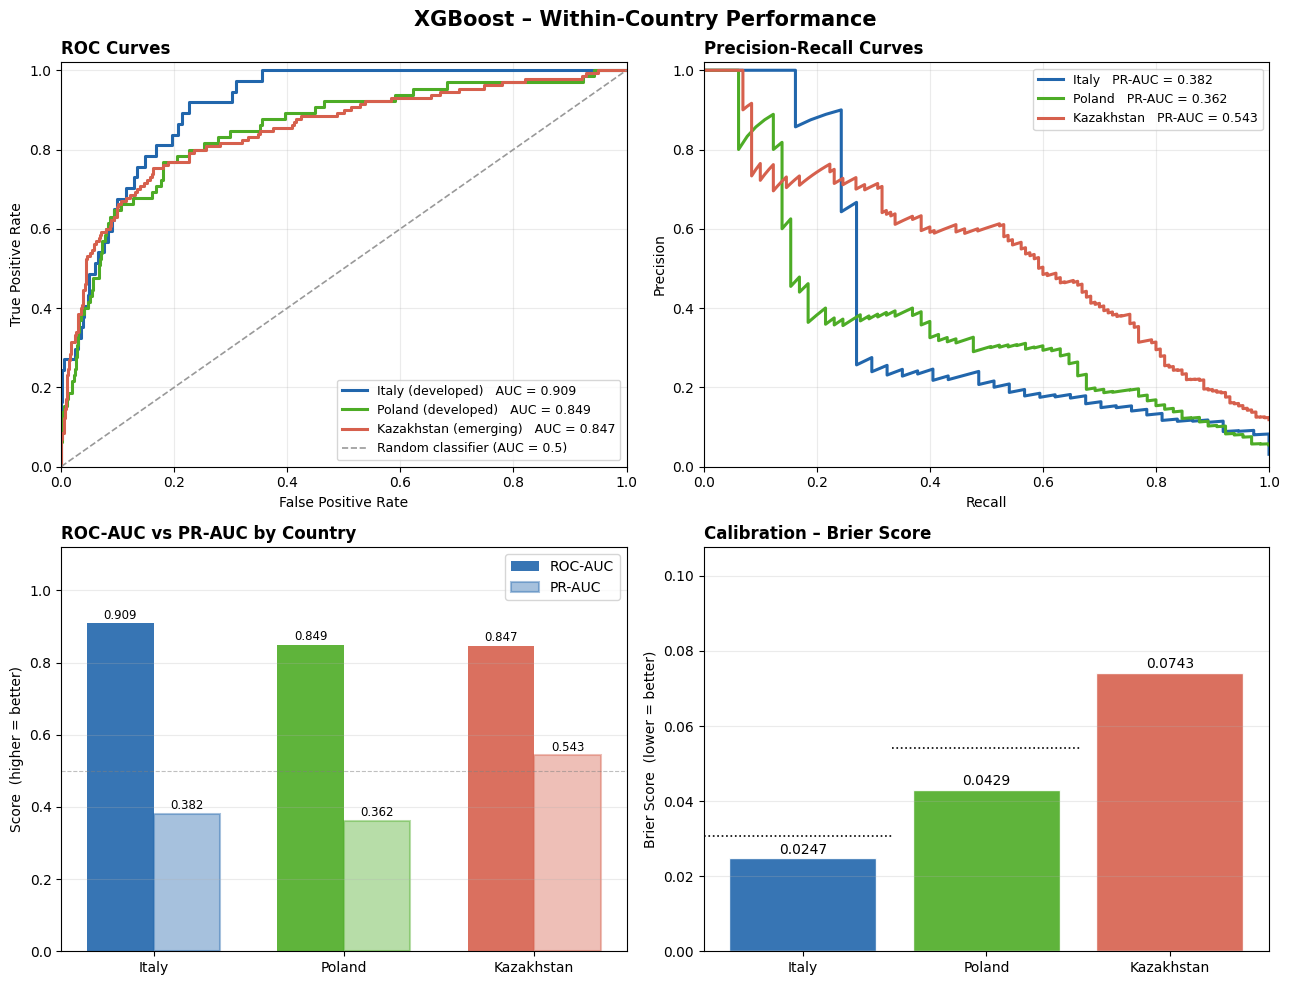

In [60]:
# STEP 4 – figures for XGBoost
fig4, axes = plt.subplots(2, 2, figsize=(13, 10))
fig4.suptitle("XGBoost – Within-Country Performance",
              fontsize=15, fontweight="bold")

# Chart 4a: ROC curves
ax = axes[0, 0]
for c in COUNTRY_ORDER:
    r = xgb_results[c]
    ax.plot(r["fpr"], r["tpr"],
            color=COLORS[c], lw=2.2,
            label=f"{c} ({MARKET_TYPE[c]})   AUC = {r['auc']:.3f}")
ax.plot([0, 1], [0, 1], "--", color="#999999", lw=1.2, label="Random classifier (AUC = 0.5)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves", fontweight="bold", loc="left")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

# Chart 4b: Precision-Recall curves
ax = axes[0, 1]
for c in COUNTRY_ORDER:
    r = xgb_results[c]
    ax.plot(r["rec"], r["prec"],
            color=COLORS[c], lw=2.2,
            label=f"{c}   PR-AUC = {r['pr_auc']:.3f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curves", fontweight="bold", loc="left")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

# Chart 4c: ROC-AUC vs PR-AUC
ax = axes[1, 0]
x = np.arange(len(COUNTRY_ORDER))
w = 0.35

bars_roc = ax.bar(x - w/2,
                  [xgb_results[c]["auc"] for c in COUNTRY_ORDER], w,
                  color=[COLORS[c] for c in COUNTRY_ORDER],
                  alpha=0.9, label="ROC-AUC")

bars_pr = ax.bar(x + w/2,
                 [xgb_results[c]["pr_auc"] for c in COUNTRY_ORDER], w,
                 color=[COLORS[c] for c in COUNTRY_ORDER],
                 alpha=0.4, edgecolor=[COLORS[c] for c in COUNTRY_ORDER],
                 linewidth=1.5, label="PR-AUC")

label_bars(ax, list(bars_roc) + list(bars_pr))

ax.set_xticks(x)
ax.set_xticklabels(COUNTRY_ORDER)
ax.set_ylabel("Score  (higher = better)")
ax.set_title("ROC-AUC vs PR-AUC by Country", fontweight="bold", loc="left")
ax.legend()
ax.set_ylim(0, 1.12)
ax.grid(axis="y", alpha=0.25)
ax.axhline(0.5, color="grey", lw=0.8, ls="--", alpha=0.5)

# Chart 4d: Brier score
ax = axes[1, 1]
brier_vals = [xgb_results[c]["brier"] for c in COUNTRY_ORDER]

bars_b = ax.bar(COUNTRY_ORDER, brier_vals,
                color=[COLORS[c] for c in COUNTRY_ORDER],
                alpha=0.9, edgecolor="white")

label_bars(ax, bars_b, fmt=".4f", pad=0.0005, fontsize=10)

for i, c in enumerate(COUNTRY_ORDER):
    baseline = xgb_results[c]["y_test"].mean()
    ax.axhline(baseline, xmin=(i)/3, xmax=(i+1)/3,
               color="black", lw=1.2, ls="dotted")

ax.set_ylabel("Brier Score  (lower = better)")
ax.set_title("Calibration – Brier Score", fontweight="bold", loc="left")
ax.set_ylim(0, max(brier_vals) * 1.45)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

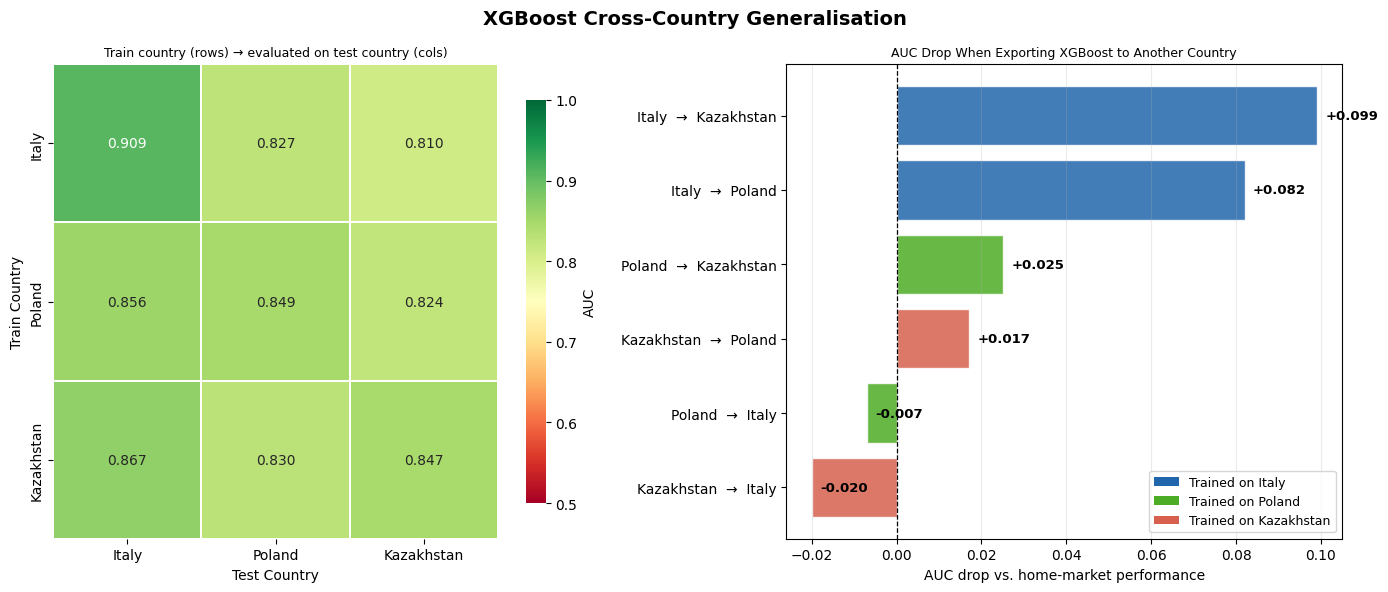

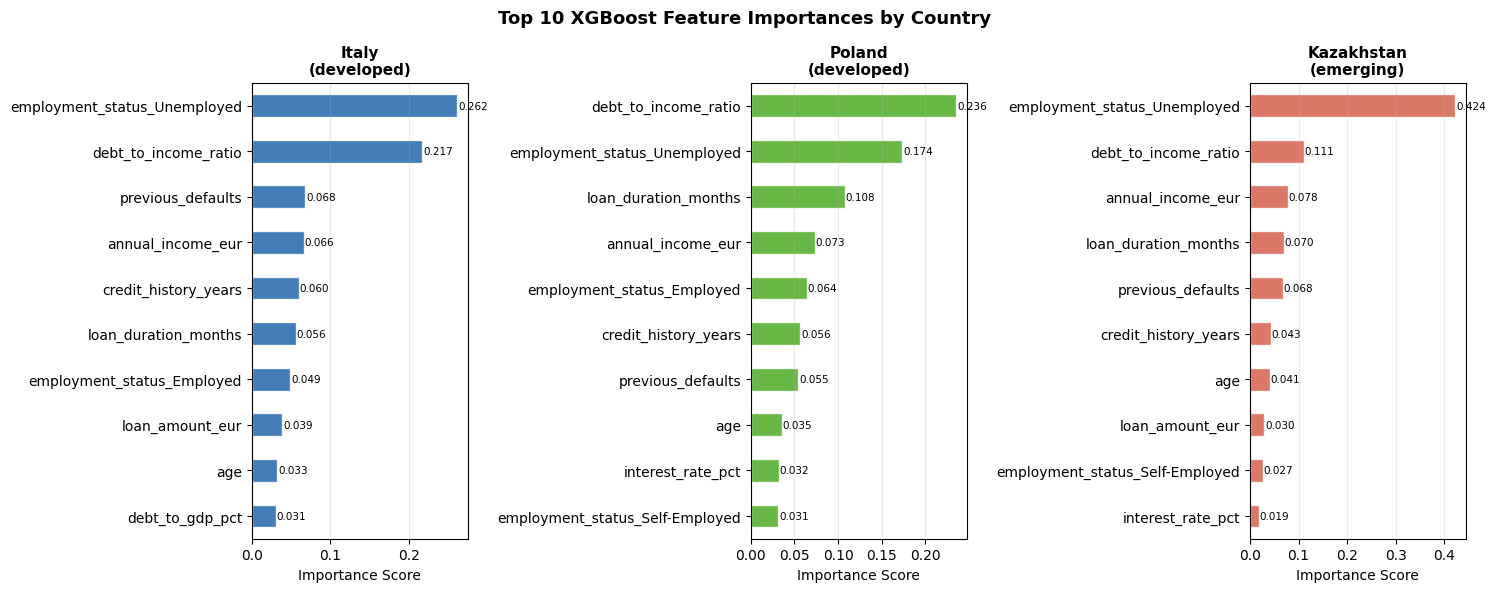

In [61]:
# STEP 5 – XGBoost cross-country transfer charts
for c in COUNTRY_ORDER:
    xgb_heatmap_data.loc[c, c] = xgb_results[c]["auc"]
xgb_heatmap_data = xgb_heatmap_data.astype(float)

fig5, axes = plt.subplots(1, 2, figsize=(14, 6))
fig5.suptitle("XGBoost Cross-Country Generalisation",
              fontsize=14, fontweight="bold")

# Chart 5a: heatmap
ax = axes[0]
sns.heatmap(xgb_heatmap_data,
            annot=True, fmt=".3f",
            cmap="RdYlGn", vmin=0.5, vmax=1.0,
            ax=ax, linewidths=1.2, linecolor="white",
            cbar_kws={"label": "AUC", "shrink": 0.85})
ax.set_title("Train country (rows) → evaluated on test country (cols)",
             fontsize=9)
ax.set_xlabel("Test Country")
ax.set_ylabel("Train Country")

# Chart 5b: AUC drop when the model is exported to another country
ax = axes[1]

drop_records = []
for tc in COUNTRY_ORDER:
    home_auc = float(xgb_heatmap_data.loc[tc, tc])
    for ec in COUNTRY_ORDER:
        if ec != tc:
            drop = home_auc - float(xgb_heatmap_data.loc[tc, ec])
            drop_records.append({
                "Label": f"{tc}  →  {ec}",
                "Drop": round(drop, 3),
                "Train": tc
            })

drop_df = pd.DataFrame(drop_records).sort_values("Drop", ascending=True)
bar_colors = [COLORS[r["Train"]] for _, r in drop_df.iterrows()]

bars = ax.barh(drop_df["Label"], drop_df["Drop"],
               color=bar_colors, alpha=0.85, edgecolor="white")

for bar, val in zip(bars, drop_df["Drop"]):
    ax.text(bar.get_width() + 0.002,
            bar.get_y() + bar.get_height() / 2,
            f"{val:+.3f}", va="center", fontsize=9.5, fontweight="bold")

ax.axvline(0, color="black", lw=0.9, ls="--")
ax.set_xlabel("AUC drop vs. home-market performance")
ax.set_title("AUC Drop When Exporting XGBoost to Another Country",
             fontsize=9)
ax.grid(axis="x", alpha=0.25)

legend_elements = [Patch(facecolor=COLORS[c], label=f"Trained on {c}") for c in COUNTRY_ORDER]
ax.legend(handles=legend_elements, fontsize=9, loc="lower right")

plt.tight_layout()
plt.show()


# STEP 6 – feature importances for XGBoost
fig6, axes = plt.subplots(1, 3, figsize=(15, 6))
fig6.suptitle("Top 10 XGBoost Feature Importances by Country",
              fontsize=13, fontweight="bold")

for ax, country in zip(axes, COUNTRY_ORDER):
    r = xgb_results[country]
    xgb_mdl = r["model"].named_steps["classifier"]
    pre_stp = r["model"].named_steps["preprocessor"]

    try:
        feat_names = pre_stp.get_feature_names_out()
    except Exception:
        feat_names = [f"feature_{i}" for i in range(len(xgb_mdl.feature_importances_))]

    clean_names = [
        n.replace("num__", "").replace("cat__", "").replace("_x0_", "=")
        for n in feat_names
    ]

    importances = pd.Series(xgb_mdl.feature_importances_, index=clean_names)
    top10 = importances.nlargest(10).sort_values()

    top10.plot.barh(ax=ax, color=COLORS[country], alpha=0.85, edgecolor="white")
    ax.set_title(f"{country}\n({MARKET_TYPE[country]})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Importance Score")
    ax.grid(axis="x", alpha=0.25)

    for i, val in enumerate(top10.values):
        ax.text(val + 0.001, i, f"{val:.3f}", va="center", fontsize=7.5)

plt.tight_layout()
plt.show()

In [62]:
# COMPARISON, SUMMARY, AND OVERFITTING CHECK

# This section compares Logistic Regression, Random Forest, and XGBoost using within-country and cross-country ROC-AUC.
# It also checks whether models may be overfitting by comparing training AUC and test AUC.

# 1. WITHIN-COUNTRY MODEL COMPARISON

comparison_records = []

for country in COUNTRY_ORDER:

    comparison_records.append({
        "Country": country,
        "Model": "Logistic Regression",
        "ROC-AUC": lr_results[country]["auc"]
    })

    comparison_records.append({
        "Country": country,
        "Model": "Random Forest",
        "ROC-AUC": results[country]["auc"]
    })

    comparison_records.append({
        "Country": country,
        "Model": "XGBoost",
        "ROC-AUC": xgb_results[country]["auc"]
    })

comparison_df = pd.DataFrame(comparison_records)

print("WITHIN-COUNTRY MODEL COMPARISON")
display(comparison_df.round(4))

# 2. AVERAGE MODEL PERFORMANCE SUMMARY
# Calculates average ROC-AUC across all countries

model_summary = (
    comparison_df
    .groupby("Model")
    .agg(
        Mean_ROC_AUC=("ROC-AUC", "mean"),
        Std_ROC_AUC=("ROC-AUC", "std")
    )
    .sort_values("Mean_ROC_AUC", ascending=False)
)

print("AVERAGE MODEL PERFORMANCE SUMMARY")
display(model_summary.round(4))

# 3. CROSS-COUNTRY SUMMARY

# Uses only off-diagonal values:
# train on one country -> test on another country

def off_diagonal_mean(matrix):

    values = []

    for train_country in COUNTRY_ORDER:
        for test_country in COUNTRY_ORDER:

            if train_country != test_country:
                values.append(float(matrix.loc[train_country, test_country]))

    return np.mean(values)


cross_country_summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],

    "Average Within-country AUC": [
        np.mean([lr_results[c]["auc"] for c in COUNTRY_ORDER]),
        np.mean([results[c]["auc"] for c in COUNTRY_ORDER]),
        np.mean([xgb_results[c]["auc"] for c in COUNTRY_ORDER])
    ],

    "Average Cross-country AUC": [
        off_diagonal_mean(cross_country_auc),
        off_diagonal_mean(heatmap_data),
        off_diagonal_mean(xgb_heatmap_data)
    ]
})

# Difference between same-country and cross-country performance
cross_country_summary["Generalisation Gap"] = (
    cross_country_summary["Average Within-country AUC"]
    - cross_country_summary["Average Cross-country AUC"]
)

print("CROSS-COUNTRY GENERALISATION SUMMARY")
display(cross_country_summary.round(4))

# 4. OVERFITTING CHECK
# Compares train ROC-AUC and test ROC-AUC.
# Large gaps may indicate overfitting.

overfit_records = []

for country in COUNTRY_ORDER:

    # Logistic Regression

    group_lr = df_lr[df_lr["country"] == country].copy()

    X_lr = group_lr.drop(columns=[TARGET_COLUMN])
    y_lr = group_lr[TARGET_COLUMN]

    X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
        X_lr,
        y_lr,
        test_size=0.2,
        stratify=y_lr,
        random_state=42
    )

    lr_model = clone(base_model)
    lr_model.fit(X_train_lr, y_train_lr)

    train_auc_lr = roc_auc_score(
        y_train_lr,
        lr_model.predict_proba(X_train_lr)[:, 1]
    )

    test_auc_lr = roc_auc_score(
        y_test_lr,
        lr_model.predict_proba(X_test_lr)[:, 1]
    )

    overfit_records.append({
        "Country": country,
        "Model": "Logistic Regression",
        "Train AUC": train_auc_lr,
        "Test AUC": test_auc_lr,
        "Gap": train_auc_lr - test_auc_lr
    })


    # Random Forest

    group_rf = full_df[full_df["country"] == country].copy()

    X_rf = group_rf.drop(columns=[TARGET_COLUMN])
    y_rf = group_rf[TARGET_COLUMN]

    X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
        X_rf,
        y_rf,
        test_size=0.2,
        stratify=y_rf,
        random_state=42
    )

    rf_model = build_rf_pipeline()
    rf_model.fit(X_train_rf, y_train_rf)

    train_auc_rf = roc_auc_score(
        y_train_rf,
        rf_model.predict_proba(X_train_rf)[:, 1]
    )

    test_auc_rf = roc_auc_score(
        y_test_rf,
        rf_model.predict_proba(X_test_rf)[:, 1]
    )

    overfit_records.append({
        "Country": country,
        "Model": "Random Forest",
        "Train AUC": train_auc_rf,
        "Test AUC": test_auc_rf,
        "Gap": train_auc_rf - test_auc_rf
    })


    # XGBoost

    group_xgb = full_df[full_df["country"] == country].copy()

    X_xgb = group_xgb.drop(columns=[TARGET_COLUMN])
    y_xgb = group_xgb[TARGET_COLUMN]

    X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(
        X_xgb,
        y_xgb,
        test_size=0.2,
        stratify=y_xgb,
        random_state=42
    )

    xgb_model = build_xgb_pipeline(y_train_xgb)
    xgb_model.fit(X_train_xgb, y_train_xgb)

    train_auc_xgb = roc_auc_score(
        y_train_xgb,
        xgb_model.predict_proba(X_train_xgb)[:, 1]
    )

    test_auc_xgb = roc_auc_score(
        y_test_xgb,
        xgb_model.predict_proba(X_test_xgb)[:, 1]
    )

    overfit_records.append({
        "Country": country,
        "Model": "XGBoost",
        "Train AUC": train_auc_xgb,
        "Test AUC": test_auc_xgb,
        "Gap": train_auc_xgb - test_auc_xgb
    })


overfit_df = pd.DataFrame(overfit_records)

print("OVERFITTING CHECK")
display(overfit_df.round(4))

# 5. AUTOMATIC INTERPRETATION
print("\nSUMMARY INTERPRETATION")

# Best within-country model
best_model = model_summary.index[0]

print(f"\nBest average within-country model: {best_model}")


# Best cross-country transfer model
best_transfer_model = cross_country_summary.sort_values(
    "Average Cross-country AUC",
    ascending=False
).iloc[0]["Model"]

print(f"Best cross-country generalisation model: {best_transfer_model}")


# Overfitting interpretation
print("\nOverfitting interpretation:")
# Small gaps are expected because models naturally perform better on training data than on unseen test data.

# Approximate interpretation used here:
# Gap < 0.05  -> no serious overfitting
# Gap 0.05-0.10 -> mild/moderate overfitting
# Gap > 0.10 -> possible strong overfitting

# These thresholds are not strict mathematical rules,but practical guidelines commonly used in applied machine learning
for _, row in overfit_df.iterrows():

    if row["Gap"] > 0.10:
        status = "possible overfitting"

    elif row["Gap"] > 0.05:
        status = "mild overfitting"

    else:
        status = "no serious overfitting"

    print(
        f"{row['Model']} in {row['Country']}: "
        f"Train AUC = {row['Train AUC']:.3f}, "
        f"Test AUC = {row['Test AUC']:.3f}, "
        f"Gap = {row['Gap']:.3f} → {status}"
    )

WITHIN-COUNTRY MODEL COMPARISON


,Country,Model,ROC-AUC
0,Italy,Logistic Regression,0.9040
1,Italy,Random Forest,0.9250
2,Italy,XGBoost,0.9086
3,Poland,Logistic Regression,0.8510
4,Poland,Random Forest,0.8242
5,Poland,XGBoost,0.8487
6,Kazakhstan,Logistic Regression,0.8540
7,Kazakhstan,Random Forest,0.8451
8,Kazakhstan,XGBoost,0.8472


AVERAGE MODEL PERFORMANCE SUMMARY


,Mean_ROC_AUC,Std_ROC_AUC
Model,,
Logistic Regression,0.8697,0.0297
XGBoost,0.8682,0.0350
Random Forest,0.8647,0.0532


CROSS-COUNTRY GENERALISATION SUMMARY


,Model,Average Within-country AUC,Average Cross-country AUC,Generalisation Gap
0,Logistic Regression,0.8697,0.8512,0.0184
1,Random Forest,0.8647,0.8413,0.0234
2,XGBoost,0.8682,0.8357,0.0325


OVERFITTING CHECK


,Country,Model,Train AUC,Test AUC,Gap
0,Italy,Logistic Regression,0.8863,0.9061,-0.0198
1,Italy,Random Forest,0.9676,0.9250,0.0426
2,Italy,XGBoost,0.9483,0.9086,0.0397
3,Poland,Logistic Regression,0.8459,0.8507,-0.0048
4,Poland,Random Forest,0.9343,0.8242,0.1102
5,Poland,XGBoost,0.9140,0.8487,0.0653
6,Kazakhstan,Logistic Regression,0.8418,0.8527,-0.0109
7,Kazakhstan,Random Forest,0.8938,0.8451,0.0487
8,Kazakhstan,XGBoost,0.8850,0.8472,0.0378



SUMMARY INTERPRETATION

Best average within-country model: Logistic Regression
Best cross-country generalisation model: Logistic Regression

Overfitting interpretation:
Logistic Regression in Italy: Train AUC = 0.886, Test AUC = 0.906, Gap = -0.020 → no serious overfitting
Random Forest in Italy: Train AUC = 0.968, Test AUC = 0.925, Gap = 0.043 → no serious overfitting
XGBoost in Italy: Train AUC = 0.948, Test AUC = 0.909, Gap = 0.040 → no serious overfitting
Logistic Regression in Poland: Train AUC = 0.846, Test AUC = 0.851, Gap = -0.005 → no serious overfitting
Random Forest in Poland: Train AUC = 0.934, Test AUC = 0.824, Gap = 0.110 → possible overfitting
XGBoost in Poland: Train AUC = 0.914, Test AUC = 0.849, Gap = 0.065 → mild overfitting
Logistic Regression in Kazakhstan: Train AUC = 0.842, Test AUC = 0.853, Gap = -0.011 → no serious overfitting
Random Forest in Kazakhstan: Train AUC = 0.894, Test AUC = 0.845, Gap = 0.049 → no serious overfitting
XGBoost in Kazakhstan: Train AUC

Logistic Regression exhibited the smallest train-test performance gaps across all countries, suggesting strong generalization and limited overfitting. In contrast, Random Forest and XGBoost demonstrated larger gaps, particularly in Poland, indicating that more flexible tree-based models were more prone to fitting country-specific patterns.

The results suggest that simpler linear models may capture more stable financial relationships that transfer better across countries, whereas more complex nonlinear models achieve stronger local fitting at the cost of reduced generalizability.